# Fase 2: Tuning de Hiperparámetros con GridSearchCV

**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025  
**Objetivo de este notebook:** Optimizar los hiperparámetros de los 6 modelos  
**Input:** `model_dataset_selected.csv` (generado en 03_feature_selection.ipynb)  
**Output:** Modelos optimizados + métricas por fold

---

## ¿Qué es el Tuning de Hiperparámetros?

Los **hiperparámetros** son configuraciones que definimos **antes** de entrenar el modelo. No se aprenden de los datos, sino que son "knobs" que ajustamos.

### Ejemplo:

```python
# Hiperparámetros de Random Forest
RandomForestClassifier(
    n_estimators=400,    # ¿Cuántos árboles?
    max_depth=12,        # ¿Qué tan profundos?
    min_samples_leaf=4   # ¿Mínimo de muestras por hoja?
)
```

### ¿Por qué optimizarlos?

- **Valores por defecto** no siempre son los mejores para nuestros datos
- Un buen tuning puede mejorar **2-5 puntos** en accuracy/F1
- Evita **overfitting** (complejidad excesiva) o **underfitting** (demasiado simple)

## ¿Qué es GridSearchCV?

**GridSearchCV** prueba **todas las combinaciones** de hiperparámetros que le definimos:

```python
param_grid = {
    'n_estimators': [100, 200, 400],  # 3 opciones
    'max_depth': [8, 12, 16]          # 3 opciones
}
# Total: 3 x 3 = 9 combinaciones
```

Para cada combinación:
1. Entrena el modelo con **validación cruzada** (CV)
2. Calcula el score promedio
3. Se queda con la mejor combinación

### ¿Por qué no solo probar manualmente?

- **Tarda menos**: Paraleliza el entrenamiento
- **Es sistemático**: No olvida combinaciones
- **Usa CV**: Evita que el resultado dependa de un solo split

## Estrategia de Validación: Expanding Window

En lugar de un solo split, usamos **múltiples folds temporales**:

| Fold | Train | Test |
|------|-------|------|
| 1 | 2017-2018 | 2018-2019 |
| 2 | [2017-2019] | 2019-2020 |
| 3 | [2017-2020] | 2020-2021 |
| 4 | [2017-2021] | 2021-2022 |
| 5 | [2017-2022] | 2022-2023 |
| 6 | [2017-2023] | 2023-2024 |
| 7 | [2017-2024] | 2024-2025 |

Esto simula cómo funcionaría el modelo en producción.

---
## 1. Carga de Datos y Configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
import json
warnings.filterwarnings('ignore')

# Configuración de visualización
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

# Modelos de sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, brier_score_loss

# PyTorch para red neuronal
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Utilidades personalizadas
import sys
sys.path.insert(0, '.')
from utils.split_utils import expanding_window_split, print_fold_summary
from utils.evaluation_utils import evaluate_model, compare_models

print('Librerías cargadas exitosamente.')
print(f'PyTorch version: {torch.__version__}')
print(f'GPU disponible: {torch.cuda.is_available()}')

Librerías cargadas exitosamente.
PyTorch version: 2.13.0+cpu
GPU disponible: False


In [2]:
import sys
sys.path.insert(0, '.')
from utils.evaluation_utils import leer_baseline
BASELINE_ACC = leer_baseline()   # accuracy del mercado, calculada en 01_eda.ipynb


In [3]:
# Cargar dataset con features seleccionadas
df = pd.read_csv('Dataset/model_dataset_selected.csv')

TARGET = 'target_home_win'

# Generar folds (necesita season)
folds = expanding_window_split(df, min_train_seasons=1)
print_fold_summary(folds, df)

# X sin season (string, no usable por sklearn)
X = df.drop(columns=[TARGET, 'season'])
y = df[TARGET]

print(f'\n Dataset cargado:')
print(f'   Filas: {df.shape[0]:,}')
print(f'   Features: {X.shape[1]}')
print(f'   Target: {TARGET}')
print(f'   Balance: {y.mean()*100:.1f}% victorias locales')


RESUMEN DE FOLDS — EXPANDING WINDOW
Total de partidos: 2973
Total de folds: 7

Fold 1:
  Train: ['2017-2018']
         347 partidos (11.7%)
  Test:  2018-2019
         371 partidos (12.5%)

Fold 2:
  Train: ['2017-2018', '2018-2019']
         718 partidos (24.2%)
  Test:  2019-2020
         371 partidos (12.5%)

Fold 3:
  Train: ['2017-2018', '2018-2019', '2019-2020']
         1089 partidos (36.6%)
  Test:  2020-2021
         377 partidos (12.7%)

Fold 4:
  Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021']
         1466 partidos (49.3%)
  Test:  2021-2022
         377 partidos (12.7%)

Fold 5:
  Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022']
         1843 partidos (62.0%)
  Test:  2022-2023
         377 partidos (12.7%)

Fold 6:
  Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023']
         2220 partidos (74.7%)
  Test:  2023-2024
         376 partidos (12.6%)

Fold 7:
  Train: ['2017-2018', '2018-2019', '2019-2020',

---
## 2. Definición de Modelos y Grids de Hiperparámetros

### ¿Por qué definir grids específicos?

Cada modelo tiene hiperparámetros diferentes. Debemos definir:
- **Rangos razonables**: No demasiado amplios (tarda mucho)
- **Valores estándar**: Incluir los valores por defecto
- **Escalas**: Algunos hiperparámetros son logarítmicos (ej: C en SVM)

In [4]:
# Definir modelos y sus grids de hiperparámetros

model_configs = {
    'Regresión Logística': {
        'model': LogisticRegression(
            max_iter=1000,
            random_state=42,
            class_weight='balanced'
        ),
        'param_grid': {
            'C': [0.01, 0.1, 1, 10, 100],  # Regularización
            'penalty': ['l1', 'l2'],         # Tipo de regularización
        },
        'needs_scaling': True,  # SVM y LogReg necesitan escalado
        'description': 'Modelo lineal simple, interpretable'
    },
    
    'Random Forest': {
        'model': RandomForestClassifier(
            random_state=42,
            n_jobs=-1,
            class_weight='balanced'
        ),
        'param_grid': {
            'n_estimators': [200, 400, 600],  # Número de árboles
            'max_depth': [8, 12, 16, None],   # Profundidad máxima
            'min_samples_leaf': [2, 4, 8],    # Mínimo por hoja
        },
        'needs_scaling': False,  # Árboles no necesitan escalado
        'description': 'Ensemble de árboles, robusto y estable'
    },
    
    'SVM (RBF)': {
        'model': SVC(
            kernel='rbf',
            probability=True,
            random_state=42,
            class_weight='balanced'
        ),
        'param_grid': {
            'C': [0.1, 1, 10, 100],                    # Regularización
            'gamma': ['scale', 'auto', 0.01, 0.1],     # Kernel width
        },
        'needs_scaling': True,
        'description': 'Kernel no lineal, bueno con features many'
    },
    
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(
            random_state=42
        ),
        'param_grid': {
            'n_estimators': [200, 400, 600],     # Número de árboles
            'learning_rate': [0.01, 0.05, 0.1],  # Tasa de aprendizaje
            'max_depth': [3, 4, 5],              # Profundidad máxima
            'subsample': [0.7, 0.8, 0.9],        # Submuestreo
        },
        'needs_scaling': False,
        'description': 'Boosting secuencial, alto rendimiento'
    },
    
    'MLP (sklearn)': {
        'model': MLPClassifier(
            max_iter=500,
            random_state=42,
            early_stopping=True,
            validation_fraction=0.1
        ),
        'param_grid': {
            'hidden_layer_sizes': [(128, 64), (256, 128, 64), (256, 128, 64, 32)],
            'alpha': [1e-4, 1e-3, 1e-2],              # Regularización L2
            'learning_rate_init': [0.001, 0.01],      # Tasa de aprendizaje inicial
        },
        'needs_scaling': True,  # Redes neuronales SIEMPRE necesitan escalado
        'description': 'Red neuronal feed-forward'
    },
}

print(' Modelos configurados:')
print('='*70)
for name, config in model_configs.items():
    n_combos = 1
    for v in config['param_grid'].values():
        n_combos *= len(v)
    print(f'\n {name}:')
    print(f'   Descripción: {config["description"]}')
    print(f'   Necesita escalado: {config["needs_scaling"]}')
    print(f'   Combinaciones a probar: {n_combos}')

 Modelos configurados:

 Regresión Logística:
   Descripción: Modelo lineal simple, interpretable
   Necesita escalado: True
   Combinaciones a probar: 10

 Random Forest:
   Descripción: Ensemble de árboles, robusto y estable
   Necesita escalado: False
   Combinaciones a probar: 36

 SVM (RBF):
   Descripción: Kernel no lineal, bueno con features many
   Necesita escalado: True
   Combinaciones a probar: 16

 Gradient Boosting:
   Descripción: Boosting secuencial, alto rendimiento
   Necesita escalado: False
   Combinaciones a probar: 81

 MLP (sklearn):
   Descripción: Red neuronal feed-forward
   Necesita escalado: True
   Combinaciones a probar: 18


### Red Neuronal PyTorch (Configuración Manual)

La red neuronal de PyTorch no es compatible con `GridSearchCV` de sklearn, así que usaremos **Optuna** o una búsqueda manual.

In [5]:
class FootballNet(nn.Module):
    """
    Red neuronal feed-forward con BatchNorm y Dropout.
    
    Arquitectura:
    - 4 capas ocultas (256→128→64→32)
    - BatchNorm: Estabiliza el entrenamiento
    - Dropout: Previene overfitting
    - Activación: ReLU
    - Salida: Sigmoid (probabilidad 0-1)
    """
    def __init__(self, n_in, hidden_sizes=(256, 128, 64, 32), dropout_rates=(0.3, 0.25, 0.2)):
        super().__init__()
        layers = []
        prev_size = n_in
        
        for i, (size, drop) in enumerate(zip(hidden_sizes, dropout_rates + (0.0,))):
            layers.extend([
                nn.Linear(prev_size, size),
                nn.BatchNorm1d(size),
                nn.ReLU(),
                nn.Dropout(drop)
            ])
            prev_size = size
        
        layers.append(nn.Linear(prev_size, 1))
        layers.append(nn.Sigmoid())
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x).squeeze(1)


def train_pytorch_model(
    X_tr, y_tr, X_te, y_te,
    n_epochs=120,
    lr=1e-3,
    batch_size=64,
    patience=15,
    weight_decay=1e-4
):
    """
    Entrena la red neuronal PyTorch con early stopping.
    
    Early stopping: Si el loss de validación no mejora por `patience` épocas,
    detenemos el entrenamiento para evitar overfitting.
    """
    # Convertir a tensores
    X_tr_t = torch.FloatTensor(X_tr)
    y_tr_t = torch.FloatTensor(y_tr.values)
    X_te_t = torch.FloatTensor(X_te)
    y_te_t = torch.FloatTensor(y_te.values)
    
    # Crear modelo
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = FootballNet(X_tr.shape[1]).to(device)
    X_tr_t, X_te_t = X_tr_t.to(device), X_te_t.to(device)
    y_tr_t = y_tr_t.to(device)
    y_te_t = y_te_t.to(device)
    
    # Optimizador y scheduler
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=40, gamma=0.5)
    criterion = nn.BCELoss()
    
    # DataLoader
    dataset = TensorDataset(X_tr_t, y_tr_t)
    # BatchNorm falla si el último lote tiene 1 solo ejemplo: se descarta solo en ese caso
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=(len(dataset) % batch_size == 1))
    
    # Early stopping
    best_loss = float('inf')
    patience_counter = 0
    best_state = None
    
    history = []
    
    for epoch in range(n_epochs):
        # Entrenamiento
        model.train()
        epoch_loss = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        
        scheduler.step()
        
        # Validación
        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_te_t), y_te_t).item()
        
        history.append({
            'epoch': epoch + 1,
            'train_loss': epoch_loss / len(loader),
            'val_loss': val_loss
        })
        
        # Early stopping check
        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            patience_counter = 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break
    
    # Cargar mejor modelo
    if best_state:
        model.load_state_dict(best_state)
    
    # Predicciones
    model.eval()
    with torch.no_grad():
        y_proba = model(X_te_t).cpu().numpy()
        y_pred = (y_proba >= 0.5).astype(int)
    
    return y_pred, y_proba, model, pd.DataFrame(history)

print('Red neuronal PyTorch definida.')

Red neuronal PyTorch definida.


---
## 3. Tuning por Fold (Expanding Window)

### ¿Por qué tuning por fold?

En lugar de optimizar una vez y evaluar en un solo test, hacemos:

1. Para cada fold:
   - Entrenar con datos de entrenamiento del fold
   - Usar **GridSearchCV interno** (con TimeSeriesSplit) para encontrar mejores hiperparámetros
   - Evaluar en el test del fold

2. Promediar resultados across folds

Esto nos da una estimación más robusta del rendimiento real.

In [6]:
# Almacenar resultados
all_results = []
best_models = {}  # Guardar mejores modelos por fold

print(' INICIANDO TUNING POR FOLD')
print('='*70)
print(f' Total de folds: {len(folds)}')
print(f' Modelos a optimizar: {len(model_configs)}')
print('='*70)

total_start = time.time()

for fold_idx, (train_idx, test_idx, train_s, test_s) in enumerate(folds):
    fold_start = time.time()
    
    print(f'\n--- FOLD {fold_idx + 1}/{len(folds)} ---')
    print(f'   Train: {train_s} ({len(train_idx)} partidos)')
    print(f'   Test:  {test_s} ({len(test_idx)} partidos)')
    
    # Dividir datos
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y.iloc[test_idx]
    
    # Escalar si es necesario (global scaler)
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)
    
    # Entrenar cada modelo
    for model_name, config in model_configs.items():
        print(f'\n   {model_name}...')
        
        # Preparar datos (escalados o no)
        if config['needs_scaling']:
            X_tr = X_train_sc
            X_te = X_test_sc
        else:
            X_tr = X_train.values
            X_te = X_test.values
        
        # GridSearchCV con TimeSeriesSplit interno
        inner_cv = TimeSeriesSplit(n_splits=3)
        
        gs = GridSearchCV(
            estimator=config['model'],
            param_grid=config['param_grid'],
            cv=inner_cv,
            scoring='f1',
            n_jobs=-1,
            refit=True,
            verbose=0
        )
        
        start = time.time()
        gs.fit(X_tr, y_train)
        fit_time = time.time() - start
        
        # Predicciones
        y_pred = gs.predict(X_te)
        y_proba = gs.predict_proba(X_te)[:, 1]
        
        # Métricas
        metrics = evaluate_model(y_test, y_pred, y_proba, model_name)
        metrics['fold'] = fold_idx + 1
        metrics['train_seasons'] = str(train_s)
        metrics['test_season'] = str(test_s)
        metrics['best_params'] = str(gs.best_params_)
        metrics['best_score_cv'] = gs.best_score_
        metrics['fit_time'] = fit_time
        
        all_results.append(metrics)
        
        # Guardar modelo
        key = f'{model_name}_fold{fold_idx+1}'
        best_models[key] = {
            'model': gs.best_estimator_,
            'params': gs.best_params_,
            'scaler': scaler if config['needs_scaling'] else None
        }
        
        print(f'      CV F1: {gs.best_score_:.4f} | Test F1: {metrics["f1_score"]:.4f} | Params: {gs.best_params_}')
    
    fold_time = time.time() - fold_start
    print(f'\n   Fold completado en {fold_time:.1f}s')

total_time = time.time() - total_start
print(f'\n{"="*70}')
print(f' TUNING COMPLETADO — Tiempo total: {total_time/60:.1f} minutos')
print(f'{"="*70}')

 INICIANDO TUNING POR FOLD
 Total de folds: 7
 Modelos a optimizar: 5

--- FOLD 1/7 ---
   Train: ['2017-2018'] (347 partidos)
   Test:  2018-2019 (371 partidos)



   Regresión Logística...


      CV F1: 0.5950 | Test F1: 0.6589 | Params: {'C': 0.01, 'penalty': 'l2'}

   Random Forest...


      CV F1: 0.5984 | Test F1: 0.6485 | Params: {'max_depth': 8, 'min_samples_leaf': 4, 'n_estimators': 200}

   SVM (RBF)...
      CV F1: 0.5799 | Test F1: 0.6382 | Params: {'C': 0.1, 'gamma': 0.1}

   Gradient Boosting...


      CV F1: 0.6092 | Test F1: 0.6098 | Params: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.9}

   MLP (sklearn)...


      CV F1: 0.6473 | Test F1: 0.5473 | Params: {'alpha': 0.0001, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.01}

   Fold completado en 43.9s

--- FOLD 2/7 ---
   Train: ['2017-2018', '2018-2019'] (718 partidos)
   Test:  2019-2020 (371 partidos)

   Regresión Logística...
      CV F1: 0.6268 | Test F1: 0.6316 | Params: {'C': 0.01, 'penalty': 'l2'}

   Random Forest...


... (20 outputs left out)

      CV F1: 0.6288 | Test F1: 0.6254 | Params: {'max_depth': 8, 'min_samples_leaf': 4, 'n_estimators': 400}

   SVM (RBF)...


      CV F1: 0.6303 | Test F1: 0.6172 | Params: {'C': 1, 'gamma': 'auto'}

   Gradient Boosting...


      CV F1: 0.6080 | Test F1: 0.5909 | Params: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 600, 'subsample': 0.8}

   MLP (sklearn)...


      CV F1: 0.6210 | Test F1: 0.6087 | Params: {'alpha': 0.0001, 'hidden_layer_sizes': (256, 128, 64), 'learning_rate_init': 0.001}

   Fold completado en 97.5s

 TUNING COMPLETADO — Tiempo total: 7.2 minutos


---
## 4. Análisis de Resultados por Fold

### ¿Qué estamos viendo?

Cada fila es un modelo en un fold específico. Esto nos permite ver:
- **Estabilidad**: ¿El modelo rinde igual en todos los folds?
- **Tendencias**: ¿Mejora o empeora con más datos de entrenamiento?
- **Consistencia**: ¿Los mejores hiperparámetros son los mismos en cada fold?

In [7]:
# Crear DataFrame de resultados
df_results = pd.DataFrame(all_results)

# Guardar resultados detallados
df_results.to_csv('resultados/tuning_results_detailed.csv', index=False)

print(' RESULTADOS POR FOLD Y MODELO')
print('='*70)

# Mostrar tabla resumen
pivot = df_results.pivot_table(
    index='model',
    columns='fold',
    values=['f1_score', 'roc_auc'],
    aggfunc='first'
).round(4)

print('\n F1-Score por fold:')
print(pivot['f1_score'].to_string())

print('\n\n ROC-AUC por fold:')
print(pivot['roc_auc'].to_string())

 RESULTADOS POR FOLD Y MODELO

 F1-Score por fold:
fold                      1       2       3       4       5       6       7
model                                                                      
Gradient Boosting    0.6098  0.6095  0.4828  0.6159  0.5942  0.6270  0.5909
MLP (sklearn)        0.5473  0.5310  0.5185  0.5966  0.6240  0.6435  0.6087
Random Forest        0.6485  0.5968  0.6014  0.6278  0.6366  0.6608  0.6254
Regresión Logística  0.6589  0.6316  0.5975  0.6444  0.6535  0.6685  0.6291
SVM (RBF)            0.6382  0.6151  0.5674  0.6201  0.6393  0.6278  0.6172


 ROC-AUC por fold:
fold                      1       2       3       4       5       6       7
model                                                                      
Gradient Boosting    0.7220  0.6820  0.6281  0.7363  0.7179  0.7381  0.7065
MLP (sklearn)        0.7042  0.6422  0.6850  0.7471  0.6726  0.7503  0.7194
Random Forest        0.7445  0.7061  0.6961  0.7482  0.7232  0.7460  0.7219
Regresión Logíst

### Visualizar Evolución por Fold

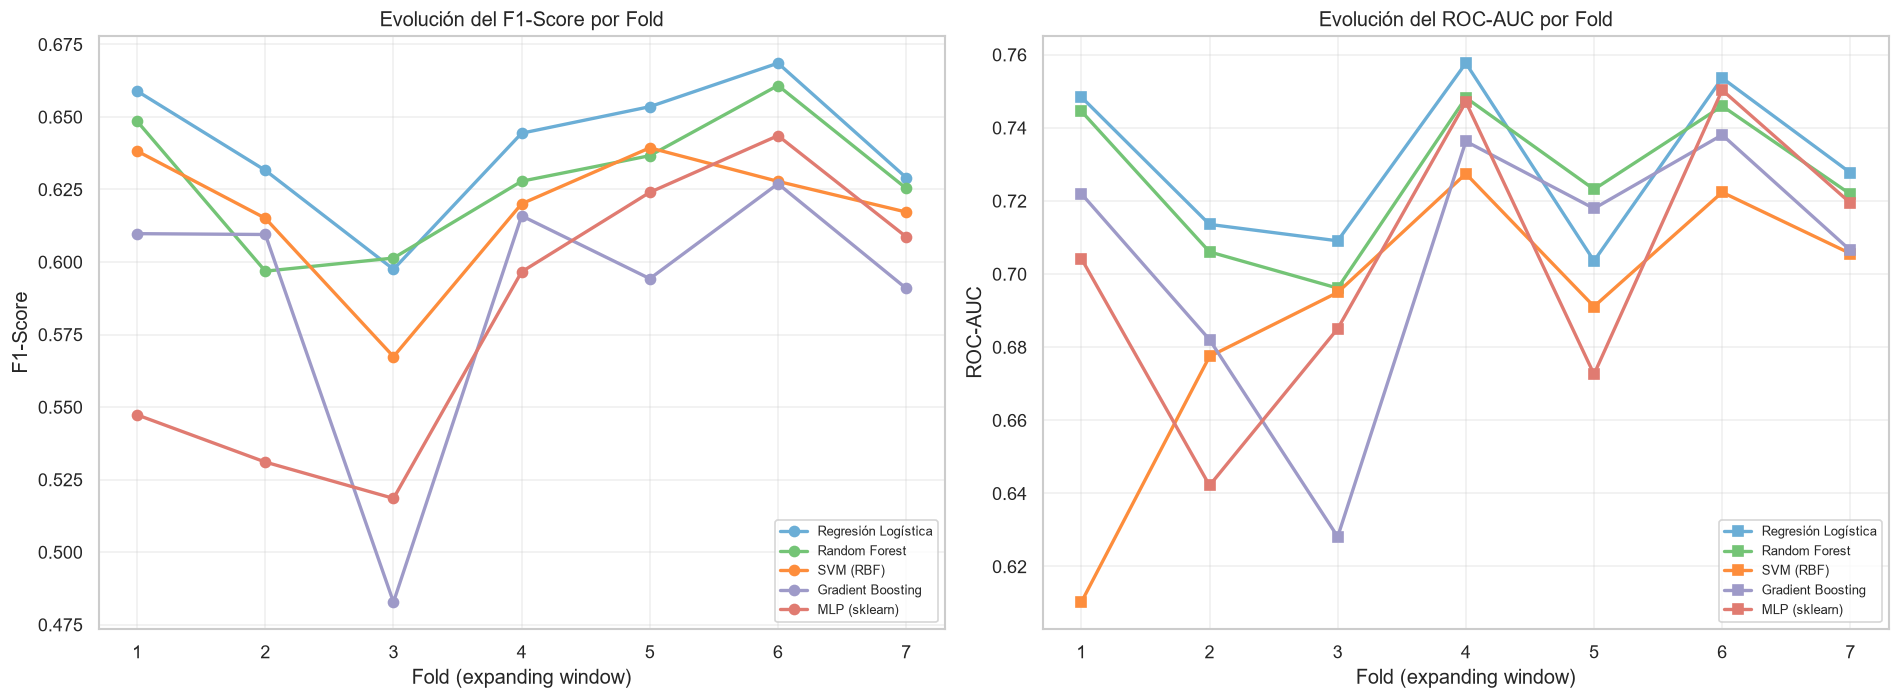

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models = df_results['model'].unique()
colors = ['#6baed6', '#74c476', '#fd8d3c', '#9e9ac8', '#e07b71']

# F1-Score por fold
for i, model in enumerate(models):
    model_data = df_results[df_results['model'] == model]
    axes[0].plot(model_data['fold'], model_data['f1_score'], 
                marker='o', color=colors[i], linewidth=2, label=model)

axes[0].set_xlabel('Fold (expanding window)')
axes[0].set_ylabel('F1-Score')
axes[0].set_title('Evolución del F1-Score por Fold', fontsize=12)
axes[0].legend(loc='lower right', fontsize=8)
axes[0].grid(True, alpha=0.3)

# ROC-AUC por fold
for i, model in enumerate(models):
    model_data = df_results[df_results['model'] == model]
    axes[1].plot(model_data['fold'], model_data['roc_auc'], 
                marker='s', color=colors[i], linewidth=2, label=model)

axes[1].set_xlabel('Fold (expanding window)')
axes[1].set_ylabel('ROC-AUC')
axes[1].set_title('Evolución del ROC-AUC por Fold', fontsize=12)
axes[1].legend(loc='lower right', fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('Imagenes/tuning/evolucion_folds.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 5. Resumen Final (Promedio across Folds)

### ¿Qué métricas reportamos?

Para cada modelo, promediamos las métricas de todos los folds:
- **Media**: Rendimiento promedio
- **Desviación estándar**: Estabilidad (menor = más estable)

### ¿Cuál es el mejor modelo?

Depende del criterio:
- **F1-Score**: Mejor balance precision/recall
- **ROC-AUC**: Mejor capacidad de discriminación
- **Brier Score**: Mejor calibración de probabilidades

In [9]:
# Calcular promedio y std por modelo
summary = df_results.groupby('model').agg({
    'accuracy': ['mean', 'std'],
    'precision': ['mean', 'std'],
    'recall': ['mean', 'std'],
    'f1_score': ['mean', 'std'],
    'roc_auc': ['mean', 'std'],
    'brier_score': ['mean', 'std'],
    'best_score_cv': ['mean', 'std']
}).round(4)

# Aplanar columnas
summary.columns = [f'{col[0]}_{col[1]}' for col in summary.columns]
summary = summary.sort_values('roc_auc_mean', ascending=False)

print(' RESUMEN FINAL — PROMEDIO ACROSS FOLDS')
print('='*70)
print(summary.to_string())

# Guardar resumen
summary.to_csv('resultados/tuning_results.csv')
print(f'\n Resumen guardado en: resultados/tuning_results.csv')

 RESUMEN FINAL — PROMEDIO ACROSS FOLDS
                     accuracy_mean  accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_score_mean  f1_score_std  roc_auc_mean  roc_auc_std  brier_score_mean  brier_score_std  best_score_cv_mean  best_score_cv_std
model                                                                                                                                                                                                                                     
Regresión Logística         0.6744        0.0119          0.6234         0.0499       0.6617      0.0240         0.6405        0.0237        0.7305       0.0226            0.2116           0.0081              0.6270             0.0151
Random Forest               0.6824        0.0124          0.6481         0.0476       0.6126      0.0358         0.6282        0.0233        0.7266       0.0206            0.2109           0.0069              0.6196             0.0126
Gradient Boosting    

### Tabla Comparativa Formateada

In [10]:
# Tabla más legible
display_cols = ['accuracy_mean', 'f1_score_mean', 'roc_auc_mean', 'brier_score_mean']
std_cols = ['accuracy_std', 'f1_score_std', 'roc_auc_std', 'brier_score_std']

print('\n TABLA COMPARATIVA FINAL (Test Set)')
print('='*70)
print(f'{"Modelo":<25} {"Accuracy":>12} {"F1-Score":>12} {"ROC-AUC":>12} {"Brier":>12}')
print('-'*70)

for idx, row in summary.iterrows():
    print(f'{idx:<25} '
          f'{row["accuracy_mean"]:.4f}±{row["accuracy_std"]:.3f} '
          f'{row["f1_score_mean"]:.4f}±{row["f1_score_std"]:.3f} '
          f'{row["roc_auc_mean"]:.4f}±{row["roc_auc_std"]:.3f} '
          f'{row["brier_score_mean"]:.4f}±{row["brier_score_std"]:.3f}')

print('\n' + '='*70)
print(f' Baseline del mercado: {BASELINE_ACC*100:.2f}% accuracy')
print('='*70)


 TABLA COMPARATIVA FINAL (Test Set)
Modelo                        Accuracy     F1-Score      ROC-AUC        Brier
----------------------------------------------------------------------
Regresión Logística       0.6744±0.012 0.6405±0.024 0.7305±0.023 0.2116±0.008
Random Forest             0.6824±0.012 0.6282±0.023 0.7266±0.021 0.2109±0.007
Gradient Boosting         0.6580±0.029 0.5900±0.049 0.7044±0.039 0.2236±0.021
MLP (sklearn)             0.6576±0.027 0.5814±0.049 0.7030±0.040 0.2271±0.026
SVM (RBF)                 0.6107±0.084 0.6179±0.024 0.6899±0.039 0.2254±0.015

 Baseline del mercado: 64.26% accuracy


---
## 6. Red Neuronal PyTorch (Tuning Manual)

Como PyTorch no es compatible con GridSearchCV, hacemos una búsqueda manual de hiperparámetros.

In [11]:
# Hiperparámetros a probar para PyTorch
pytorch_configs = [
    {'lr': 1e-3, 'batch_size': 64, 'hidden': (256, 128, 64, 32), 'dropout': (0.3, 0.25, 0.2)},
    {'lr': 5e-4, 'batch_size': 128, 'hidden': (256, 128, 64), 'dropout': (0.3, 0.25, 0.0)},
    {'lr': 1e-3, 'batch_size': 64, 'hidden': (128, 64, 32), 'dropout': (0.2, 0.2, 0.0)},
]

print(' RED NEURONAL PYTORCH — Tuning Manual')
print('='*70)

nn_results = []

for fold_idx, (train_idx, test_idx, train_s, test_s) in enumerate(folds):
    print(f'\n--- Fold {fold_idx + 1} ---')
    
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y.iloc[test_idx]
    
    # Escalar
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)
    
    best_f1 = 0
    best_config = None
    
    for config in pytorch_configs:
        # Entrenar
        y_pred, y_proba, model, hist = train_pytorch_model(
            X_train_sc, y_train, X_test_sc, y_test,
            lr=config['lr'],
            batch_size=config['batch_size']
        )
        
        f1 = f1_score(y_test, y_pred)
        
        if f1 > best_f1:
            best_f1 = f1
            best_config = config
            best_y_pred = y_pred
            best_y_proba = y_proba
            best_model = model
    
    # Métricas del mejor config
    metrics = evaluate_model(y_test, best_y_pred, best_y_proba, 'Red Neuronal (PyTorch)')
    metrics['fold'] = fold_idx + 1
    metrics['train_seasons'] = str(train_s)
    metrics['test_season'] = str(test_s)
    metrics['best_params'] = str(best_config)
    
    nn_results.append(metrics)
    
    # Guardar modelo
    torch.save(best_model.state_dict(), f'resultados/models/pytorch_fold{fold_idx+1}.pt')
    
    print(f'   Best config: {best_config}')
    print(f'   Test F1: {metrics["f1_score"]:.4f} | Test AUC: {metrics["roc_auc"]:.4f}')

# Agregar resultados de PyTorch al DataFrame principal
df_nn = pd.DataFrame(nn_results)
df_results = pd.concat([df_results, df_nn], ignore_index=True)

print(f'\n{"="*70}')
print(' Red Neuronal PyTorch completada')
print(f'{"="*70}')

 RED NEURONAL PYTORCH — Tuning Manual

--- Fold 1 ---


   Best config: {'lr': 0.001, 'batch_size': 64, 'hidden': (128, 64, 32), 'dropout': (0.2, 0.2, 0.0)}
   Test F1: 0.6350 | Test AUC: 0.7231

--- Fold 2 ---


   Best config: {'lr': 0.001, 'batch_size': 64, 'hidden': (128, 64, 32), 'dropout': (0.2, 0.2, 0.0)}
   Test F1: 0.6488 | Test AUC: 0.7209

--- Fold 3 ---


   Best config: {'lr': 0.0005, 'batch_size': 128, 'hidden': (256, 128, 64), 'dropout': (0.3, 0.25, 0.0)}
   Test F1: 0.5672 | Test AUC: 0.7117

--- Fold 4 ---


   Best config: {'lr': 0.0005, 'batch_size': 128, 'hidden': (256, 128, 64), 'dropout': (0.3, 0.25, 0.0)}
   Test F1: 0.6352 | Test AUC: 0.7489

--- Fold 5 ---


   Best config: {'lr': 0.001, 'batch_size': 64, 'hidden': (256, 128, 64, 32), 'dropout': (0.3, 0.25, 0.2)}
   Test F1: 0.6593 | Test AUC: 0.7109

--- Fold 6 ---


   Best config: {'lr': 0.001, 'batch_size': 64, 'hidden': (128, 64, 32), 'dropout': (0.2, 0.2, 0.0)}
   Test F1: 0.6388 | Test AUC: 0.7365

--- Fold 7 ---


   Best config: {'lr': 0.001, 'batch_size': 64, 'hidden': (128, 64, 32), 'dropout': (0.2, 0.2, 0.0)}
   Test F1: 0.6070 | Test AUC: 0.7242

 Red Neuronal PyTorch completada


---
## 7. Comparación Final con Baseline

### ¿Superamos al mercado?

El baseline del mercado de apuestas tiene **62.97% de accuracy**. Si nuestros modelos lo superan, significa que tienen **valor predictivo real**.

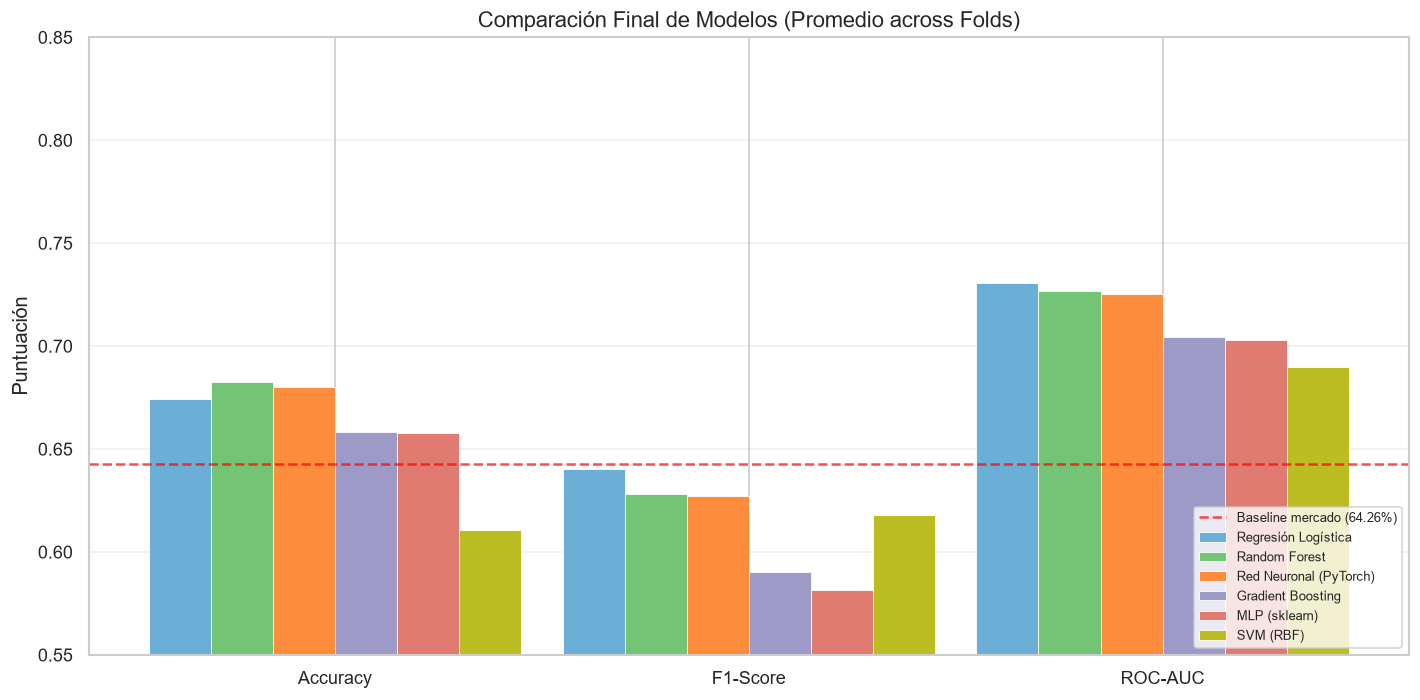

In [12]:
# Recalcular resumen con PyTorch incluido
summary_final = df_results.groupby('model').agg({
    'accuracy': ['mean', 'std'],
    'f1_score': ['mean', 'std'],
    'roc_auc': ['mean', 'std'],
    'brier_score': ['mean', 'std']
}).round(4)

summary_final.columns = [f'{col[0]}_{col[1]}' for col in summary_final.columns]
summary_final = summary_final.sort_values('roc_auc_mean', ascending=False)

# Gráfico de barras comparativo
fig, ax = plt.subplots(figsize=(12, 6))

metrics_to_plot = ['accuracy_mean', 'f1_score_mean', 'roc_auc_mean']
metric_labels = ['Accuracy', 'F1-Score', 'ROC-AUC']

x = np.arange(len(metric_labels))
width = 0.15
colors = ['#6baed6', '#74c476', '#fd8d3c', '#9e9ac8', '#e07b71', '#bcbd22']

for i, (model, row) in enumerate(summary_final.iterrows()):
    offset = (i - len(summary_final)/2 + 0.5) * width
    values = [row[m] for m in metrics_to_plot]
    ax.bar(x + offset, values, width, label=model, color=colors[i % len(colors)],
           edgecolor='white', linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(metric_labels, fontsize=11)
ax.set_ylim(0.55, 0.85)
ax.axhline(BASELINE_ACC, color='red', linestyle='--', linewidth=1.5, alpha=0.7,
           label=f'Baseline mercado ({BASELINE_ACC*100:.2f}%)')
ax.set_title('Comparación Final de Modelos (Promedio across Folds)', fontsize=13)
ax.legend(loc='lower right', fontsize=8)
ax.set_ylabel('Puntuación')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('Imagenes/tuning/comparacion_final.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 8. Guardar Modelos Finales

### ¿Por qué guardar modelos?

- **Reproducibilidad**: Podemos cargar el modelo sin re-entrenar
- **Producción**: Desplegar el modelo para predicciones reales
- **Análisis**: Examinar el modelo entrenado

In [13]:
import pickle

# Guardar modelos de sklearn
for key, model_info in best_models.items():
    filepath = f'resultados/models/{key}.pkl'
    with open(filepath, 'wb') as f:
        pickle.dump(model_info, f)
    print(f' Guardado: {filepath}')

# Guardar scaler
scaler_path = 'resultados/models/scaler.pkl'
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler, f)
print(f'\n Scaler guardado: {scaler_path}')

# Guardar resumen final
summary_final.to_csv('resultados/tuning_results_final.csv')
print(f'\n Resumen final guardado: resultados/tuning_results_final.csv')

 Guardado: resultados/models/Regresión Logística_fold1.pkl
 Guardado: resultados/models/Random Forest_fold1.pkl
 Guardado: resultados/models/SVM (RBF)_fold1.pkl
 Guardado: resultados/models/Gradient Boosting_fold1.pkl
 Guardado: resultados/models/MLP (sklearn)_fold1.pkl
 Guardado: resultados/models/Regresión Logística_fold2.pkl
 Guardado: resultados/models/Random Forest_fold2.pkl
 Guardado: resultados/models/SVM (RBF)_fold2.pkl
 Guardado: resultados/models/Gradient Boosting_fold2.pkl
 Guardado: resultados/models/MLP (sklearn)_fold2.pkl
 Guardado: resultados/models/Regresión Logística_fold3.pkl
 Guardado: resultados/models/Random Forest_fold3.pkl
 Guardado: resultados/models/SVM (RBF)_fold3.pkl
 Guardado: resultados/models/Gradient Boosting_fold3.pkl
 Guardado: resultados/models/MLP (sklearn)_fold3.pkl
 Guardado: resultados/models/Regresión Logística_fold4.pkl
 Guardado: resultados/models/Random Forest_fold4.pkl
 Guardado: resultados/models/SVM (RBF)_fold4.pkl
 Guardado: resultados/mode

---
## 9. Resumen Final

### ¿Qué logramos?

1. **Optimizamos 5 modelos** con GridSearchCV por fold
2. **Entrenamos la red neuronal PyTorch** con tuning manual
3. **Evaluamos con expanding window** (7 folds)
4. **Guardamos modelos y resultados**

### Próximos pasos:

1. **05_sin_odds.ipynb**: ¿El modelo funciona sin las odds del mercado?
2. **06_features_negativos.ipynb**: ¿Hay features que perjudican el modelo?

In [14]:
print('='*70)
print(' RESUMEN — TUNING DE HIPERPARÁMETROS')
print('='*70)
print(f'\n Modelos optimizados: {len(model_configs) + 1}')
print(f' Folds evaluados: {len(folds)}')
print(f' Tiempo total: {total_time/60:.1f} minutos')
print(f'\n Mejor modelo (por ROC-AUC): {summary_final.index[0]}')
print(f'   ROC-AUC: {summary_final.iloc[0]["roc_auc_mean"]:.4f}')
print(f'\n Mejor modelo (por F1-Score): {summary_final.sort_values("f1_score_mean", ascending=False).index[0]}')
print(f'   F1-Score: {summary_final.sort_values("f1_score_mean", ascending=False).iloc[0]["f1_score_mean"]:.4f}')
print(f'\n Baseline del mercado: {BASELINE_ACC*100:.2f}% accuracy')
print(f' Mejor accuracy: {summary_final["accuracy_mean"].max()*100:.2f}%')
print(f' Mejora sobre baseline: +{(summary_final["accuracy_mean"].max() - BASELINE_ACC)*100:.2f} puntos')
print('='*70)

 RESUMEN — TUNING DE HIPERPARÁMETROS

 Modelos optimizados: 6
 Folds evaluados: 7
 Tiempo total: 7.2 minutos

 Mejor modelo (por ROC-AUC): Regresión Logística
   ROC-AUC: 0.7305

 Mejor modelo (por F1-Score): Regresión Logística
   F1-Score: 0.6405

 Baseline del mercado: 64.26% accuracy
 Mejor accuracy: 68.24%
 Mejora sobre baseline: +3.98 puntos
